# Flower Detector Training (Oxford 102 Flowers)

Fine-tunes a small, pretrained YOLO detector to locate flower regions in a photo before classifying them. This helps with cluttered backgrounds and photos with multiple blooms of the same species, which the classifier alone struggles with.

Ran locally.

## 1. Install dependencies

In [1]:
%cd ../training

%pip install -r requirements.txt


/Users/hind/Documents/GitHub/flower-recognition/training

[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: pip3.14 install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


## 2. Download data and derive detection labels

Downloads Oxford 102's segmentation archive and derives bounding boxes per image from each trimap's foreground blob(s)

In [2]:
DATA_ROOT = "data"
DETECTION_DATA_DIR = "data/detection"

from prepare_detection_data import build_yolo_dataset

dataset_yaml = build_yolo_dataset(data_root=DATA_ROOT, out_dir=DETECTION_DATA_DIR)
print(f"Dataset config: {dataset_yaml}")


Derived 11097 boxes across 7969/8189 images (220 skipped: no foreground blob)
Wrote YOLO dataset to data/detection (6773 train / 1196 val)
Dataset config: data/detection/dataset.yaml


## 3. Verify mask-to-box derivation

mask_to_bboxes() classifies foreground pixels by color distance from Oxford
102's known trimap background color ((0, 0, 254), a near-constant solid
blue). Each connected foreground blob then gets its own box, so
images with more than one bloom produce multiple boxes instead of one box
spanning both.

Sanity-checked visually on a handful of real samples.

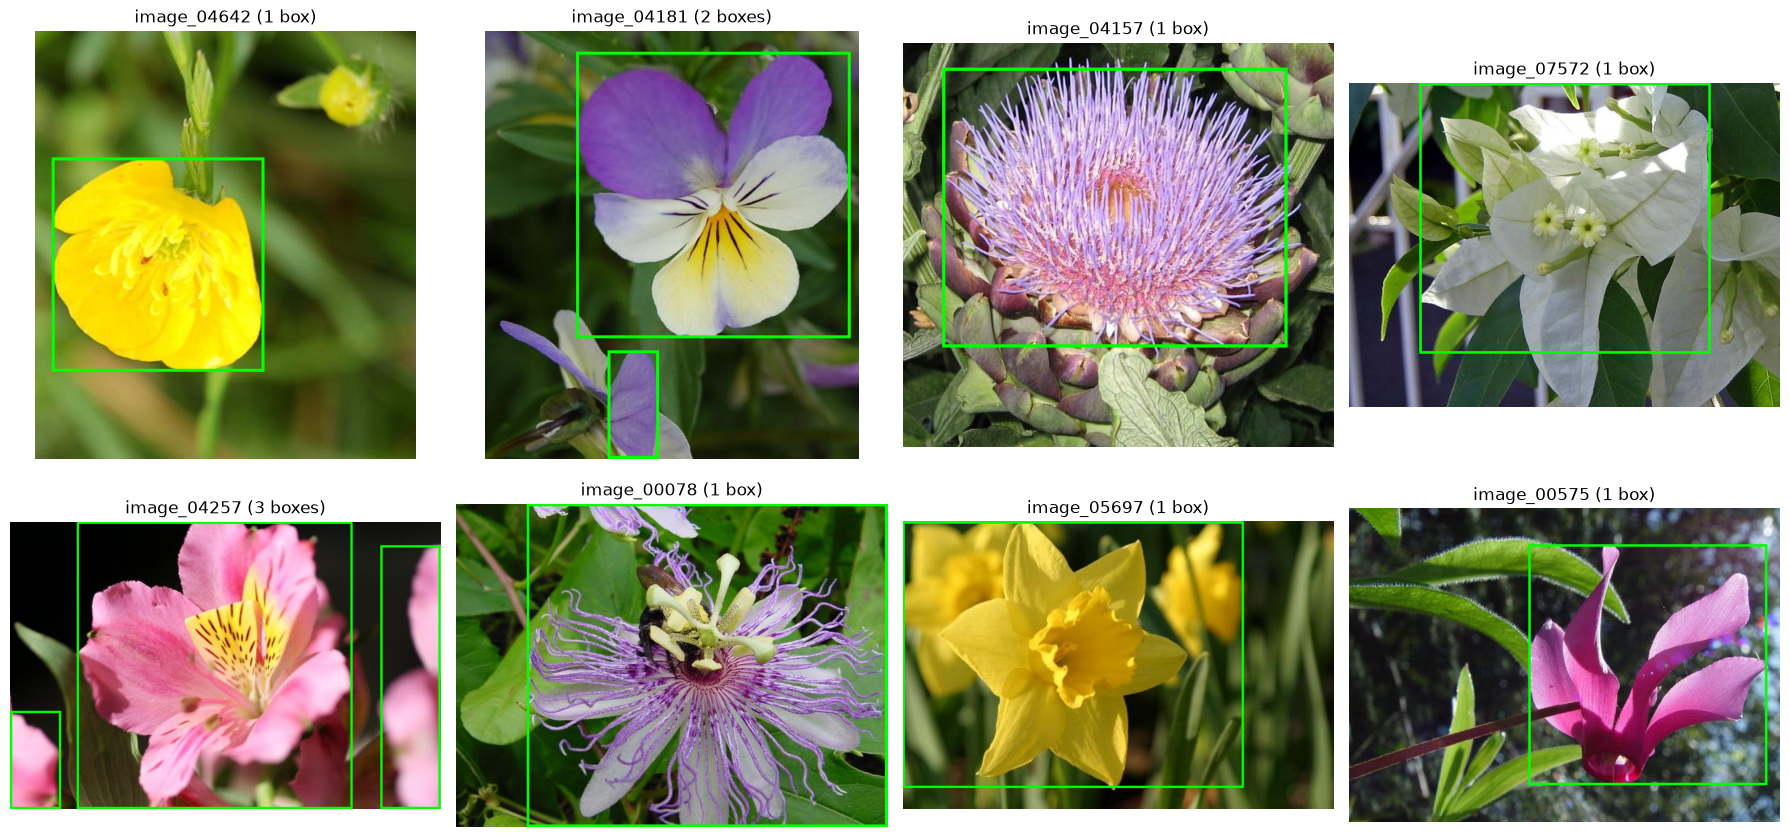

In [4]:
import random
from pathlib import Path

import matplotlib.pyplot as plt
from PIL import Image, ImageDraw

label_dir = Path(DETECTION_DATA_DIR) / "labels" / "train"
image_dir = Path(DETECTION_DATA_DIR) / "images" / "train"
sample_labels = random.sample(list(label_dir.glob("*.txt")), 8)

fig, axes = plt.subplots(2, 4, figsize=(18, 9))
for ax, label_path in zip(axes.flat, sample_labels):
    img_path = image_dir / f"{label_path.stem}.jpg"
    img = Image.open(img_path).convert("RGB")
    w, h = img.size
    draw = ImageDraw.Draw(img)
    lines = label_path.read_text().strip().splitlines()
    for line in lines:
        cls, xc, yc, bw, bh = map(float, line.split())
        x1, y1 = (xc - bw / 2) * w, (yc - bh / 2) * h
        x2, y2 = (xc + bw / 2) * w, (yc + bh / 2) * h
        draw.rectangle([x1, y1, x2, y2], outline="lime", width=4)
    ax.imshow(img)
    ax.set_title(f"{label_path.stem} ({len(lines)} box{'es' if len(lines) != 1 else ''})")
    ax.axis("off")
plt.tight_layout()
plt.show()

# If any box looks wrong (empty, covers the whole image, misses the flower
# tune BACKGROUND_TOLERANCE or min_fg_fraction in prepare_detection_data.py's mask_to_bboxes()


## 4. Train the detector

Fine-tuned from a pretrained yolo11n.pt (COCO weights, auto-downloaded on first use). A nano model keeps inference fast and CPU-friendly.

In [5]:
from train_detector import train_detector

detector_checkpoint = train_detector(
    data=str(dataset_yaml),
    model="yolo11n.pt",
    epochs=50,
    imgsz=640,
)
print(f"Best checkpoint: {detector_checkpoint}")


New https://pypi.org/project/ultralytics/8.4.184 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.180 🚀 Python-3.14.7 torch-2.14.1 CPU (Apple M5)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=data/detection/dataset.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.pt, momentum=0.937, mosaic=1.0, mu

## 5. Sanity-check predictions

Run the trained detector on a few real validation images and look at the
boxes directly.


0: 640x640 1 flower, 29.0ms
1: 640x640 4 flowers, 29.0ms
2: 640x640 1 flower, 29.0ms
3: 640x640 1 flower, 29.0ms
4: 640x640 1 flower, 29.0ms
5: 640x640 1 flower, 29.0ms
Speed: 1.0ms preprocess, 29.0ms inference, 0.3ms postprocess per image at shape (1, 3, 640, 640)


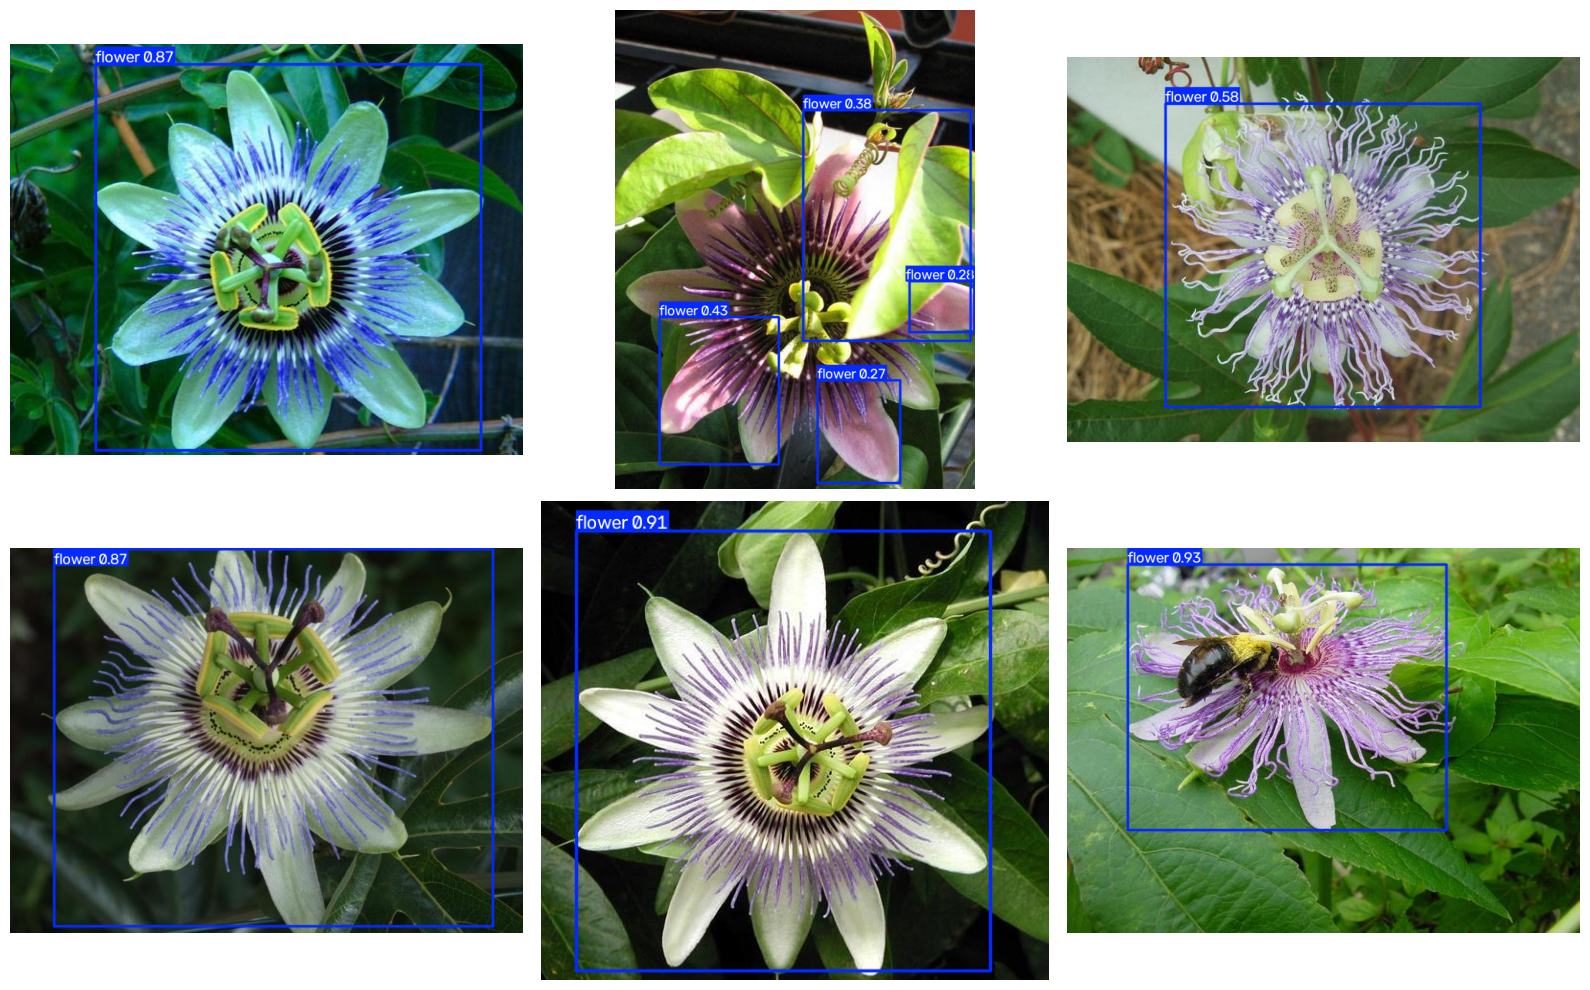

In [6]:
import glob

from ultralytics import YOLO

detector = YOLO(str(detector_checkpoint))
sample_images = sorted(glob.glob(f"{DETECTION_DATA_DIR}/images/val/*.jpg"))[:6]
results = detector.predict(sample_images, imgsz=640, conf=0.25, iou=0.45)

fig, axes = plt.subplots(2, 3, figsize=(16, 10))
for ax, result in zip(axes.flat, results):
    ax.imshow(result.plot()[..., ::-1])  # BGR -> RGB
    ax.axis("off")
plt.tight_layout()
plt.show()


## 6. Export to ONNX (NMS baked in)

Bakes non-max suppression into the ONNX graph (`nms=True`) so
`api/predict.py` never has to hand-roll it, just reads already-filtered
boxes. Runs a PyTorch-vs-ONNXRuntime parity check on real validation images.

In [3]:
detector_checkpoint = "runs/detect/runs/detect/flower_detector-2/weights/best.pt"

In [4]:
from export_detector_onnx import export

export(
    checkpoint=str(detector_checkpoint),
    out_path="../api/model/flower_detector.onnx",
    imgsz=640,
    sample_glob=f"{DETECTION_DATA_DIR}/images/val/*.jpg",
)


Ultralytics 8.4.180 🚀 Python-3.14.7 torch-2.14.1 CPU (Apple M5)
YOLO11n summary (fused): 101 layers, 2,597,051 parameters, 0 gradients, 6.4 GFLOPs

PyTorch: starting from 'runs/detect/runs/detect/flower_detector-2/weights/best.pt' with input shape (1, 3, 640, 640) BCHW and output shape(s) (1, 300, 6) (5.2 MB)

ONNX: starting export with onnx 1.23.2 opset 17...
ONNX: slimming with onnxslim 0.1.98...
ONNX: export success ✅ 0.7s, saved as 'runs/detect/runs/detect/flower_detector-2/weights/best.onnx' (10.2 MB)

Export complete (0.8s)
Results saved to /Users/hind/Documents/GitHub/flower-recognition/training/runs/detect/runs/detect/flower_detector-2/weights/best.onnx
Predict:         yolo predict task=detect model=runs/detect/runs/detect/flower_detector-2/weights/best.onnx imgsz=640 
Validate:        yolo val task=detect model=runs/detect/runs/detect/flower_detector-2/weights/best.onnx imgsz=640 data=data/detection/dataset.yaml 
Visualize:       https://netron.app
Loading ../api/model/flower

AssertionError: data/detection/images/val/image_00003.jpg: PyTorch found 3 boxes, ONNX found 4